# Семантические коды для BM25 в RAG

Каждое слово в контексте предложения превращается в бинарный код (например 10 бит, 1024 «новых слова»),
по кодам строится обычный BM25. Точные сущности идут в текст без изменений.

Весь код — в [semantic_codes.py](semantic_codes.py), здесь только запуск и проверка.

План ноутбука:
1. Настройки и данные.
2. Модель BGE-M3: векторы слов в контексте, проверка многозначности.
3. Базовые методы: BM25 по словам, dense, ColBERT.
4. Бинаризация PCA и PCA+ITQ, статистика кодов.
5. Семантические коды + BM25, перебор числа бит и хешей.
6. Автоэнкодер с бинарным слоем.
7. Точные сущности и гибрид (коды + сущности + слова), веса полей.
8. Подбор k1 и b.
9. Итоговая таблица: качество, размер индекса, скорость.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import semantic_codes as sc

pd.set_option("display.float_format", "{:.4f}".format)

## 1. Настройки и данные

`DATASET = None` — маленький встроенный набор (проверка без интернета).
Иначе любой ретривал-датасет ruMTEB в формате MTEB: `ai-forever/rubq-retrieval`, `ai-forever/ria-news-retrieval` и т.п.
Для скорости берётся `N_QUERIES` запросов, их релевантные документы и `N_DISTRACTORS` случайных документов.

In [2]:
MODEL = "BAAI/bge-m3"                    # ColBERT-голова подгружается автоматически
DATASET = "ai-forever/rubq-retrieval"    # None → sc.toy_dataset()
N_QUERIES, N_DISTRACTORS = 300, 2000
BATCH_SIZE = 32
CACHE_DIR = "cache"                      # закодированные векторы, в .gitignore

N_BITS = 10
BITS_GRID = [8, 10, 12, 14]
HASHES_GRID = [1, 2, 4]
USE_NER = True                           # natasha; без неё только регулярки

In [3]:
data = sc.load_mteb_retrieval(DATASET, N_QUERIES, N_DISTRACTORS) if DATASET else sc.toy_dataset()
print(data)
print("Пример запроса:", data.queries[0])
print("Релевантный документ:", data.docs[next(iter(data.qrels[0]))][:300])

RetrievalData(ai-forever/rubq-retrieval: 2487 docs, 300 queries, 487 qrels)
Пример запроса: Как зовут Бречалова Удмуртия?
Релевантный документ: Алекса́ндр Влади́мирович Бреча́лов (род. 18 ноября 1973, п. Тлюстенхабль, Теучежский район, Адыгейская АО, РСФСР, СССР) — российский политик. Глава Удмуртской Республики с 18 сентября 2017 (временно исполняющий обязанности главы Удмуртии с 4 апреля по 18 сентября 2017).


## 2. Модель и векторы слов

`TokenEncoder` берёт выход ColBERT-головы BGE-M3 (не сырые скрытые состояния).
Векторы токенов внутри слова усредняются: одно слово — один вектор с учётом контекста.
Документы кодируются дважды: целиком (dense и ColBERT) и по предложениям (векторы слов).
Результат кешируется в `CACHE_DIR`.

In [4]:
encoder = sc.TokenEncoder(MODEL)
print("device:", encoder.device, "| dim:", encoder.dim, "| ColBERT-голова:", encoder.colbert is not None)

device: cuda | dim: 1024 | ColBERT-голова: True


In [5]:
tag = f"{CACHE_DIR}/{data.name.replace('/', '_')}_{N_QUERIES}_{N_DISTRACTORS}_{MODEL.replace('/', '_')}"
doc_enc = sc.encode_cached(lambda: encoder, data.docs, f"{tag}_docs.pkl", batch_size=BATCH_SIZE)
q_enc = sc.encode_cached(lambda: encoder, data.queries, f"{tag}_queries.pkl", batch_size=BATCH_SIZE)
print("слов в корпусе:", len(doc_enc.word_vecs), "| в запросах:", len(q_enc.word_vecs))
print(doc_enc.words[0][:20])

[тексты] 1952/2487  7s
[предложения] 8352/8692  28s
[тексты] 32/300  0s
[предложения] 32/300  0s
слов в корпусе: 155904 | в запросах: 1846
['Следующий', 'сезон', 'ЦСКА', 'должен', 'был', 'начать', 'во', 'второй', 'лиге', 'но', 'благодаря', 'вмешательству', 'премьер-министра', 'страны', 'Бойко', 'Борисова', 'который', 'принял', 'срочные', 'и']


### Многозначность и морфология

«ключ от двери» и «ключ шифрования» должны дать разные векторы, а «ключа» / «ключом» в одном смысле — близкие.

In [6]:
demo = [
    "Я потерял ключ от входной двери.",
    "Мастер сделал дубликат ключа от квартиры.",
    "Этим ключом открыли старый замок.",
    "Ключ шифрования хранится в аппаратном модуле.",
    "Секретный ключ RSA нельзя передавать по почте.",
]
demo_enc = sc.encode_corpus(encoder, demo, verbose=False)
key_idx = [next(j for j, w in enumerate(ws) if w.lower().startswith("ключ")) for ws in demo_enc.words]
V = np.stack([demo_enc.doc_word_vecs(i)[j] for i, j in enumerate(key_idx)]).astype(np.float32)
labels = [f"{demo_enc.words[i][j]} | {demo[i][:30]}" for i, j in enumerate(key_idx)]
pd.DataFrame(V @ V.T, index=labels, columns=range(len(demo)))

,0,1,2,3,4
ключ | Я потерял ключ от входной двер,1.0000,0.7703,0.7051,0.7034,0.6288
ключа | Мастер сделал дубликат ключа о,0.7703,1.0000,0.7296,0.6803,0.5977
ключом | Этим ключом открыли старый зам,0.7051,0.7296,1.0000,0.6700,0.5376
Ключ | Ключ шифрования хранится в апп,0.7034,0.6803,0.6700,1.0000,0.6552
ключ | Секретный ключ RSA нельзя пере,0.6288,0.5977,0.5376,0.6552,1.0000


## 3. Базовые методы

In [7]:
fields_d = sc.build_fields(data.docs, doc_enc, use_ner=USE_NER)   # entities + lemmas
fields_q = sc.build_fields(data.queries, q_enc, use_ner=USE_NER)

results, sizes, speed = {}, {}, {}

bm_words = sc.BM25().fit(fields_d["lemmas"])
S_words, t = sc.timed(bm_words.score_matrix, fields_q["lemmas"])
results["BM25 по словам (леммы)"] = sc.evaluate(S_words, data.qrels)
sizes["BM25 по словам (леммы)"], speed["BM25 по словам (леммы)"] = bm_words.size_bytes(), t / len(data.queries)

S_dense, t = sc.timed(sc.dense_scores, q_enc.dense, doc_enc.dense)
results["BGE-M3 dense"] = sc.evaluate(S_dense, data.qrels)
sizes["BGE-M3 dense"], speed["BGE-M3 dense"] = doc_enc.dense.nbytes, t / len(data.queries)

S_colbert, t = sc.timed(sc.colbert_scores, q_enc.tok_vecs, doc_enc.tok_vecs)
results["BGE-M3 ColBERT"] = sc.evaluate(S_colbert, data.qrels)
sizes["BGE-M3 ColBERT"], speed["BGE-M3 ColBERT"] = sum(x.nbytes for x in doc_enc.tok_vecs), t / len(data.queries)

pd.DataFrame(results).T

,Recall@1,Recall@5,Recall@10,Recall@100,nDCG@10,MRR
BM25 по словам (леммы),0.4224,0.7418,0.7947,0.9281,0.6858,0.6915
BGE-M3 dense,0.6880,0.9463,0.9692,0.9922,0.9320,0.9403
BGE-M3 ColBERT,0.6891,0.9460,0.9758,0.9911,0.9354,0.9408


## 4. Бинаризация: PCA и ITQ

После PCA дисперсия сидит в первых компонентах, младшие биты почти шумовые.
ITQ поворачивает пространство, чтобы точки легли ближе к углам гиперкуба.
Смотрим: сколько из 2^bits кодов занято, энтропию, баланс и корреляцию бит, долю проекций около нуля.

In [8]:
X = doc_enc.word_vecs
binz = {
    "PCA": sc.PCAITQ(N_BITS, use_itq=False).fit(X),
    "PCA + случайный поворот": sc.PCAITQ(N_BITS, use_itq=False, random_rotation=True).fit(X),
    "PCA + ITQ": sc.PCAITQ(N_BITS).fit(X),
}
pd.DataFrame({name: sc.code_stats(b, X) for name, b in binz.items()}).T

,used_codes,used_share,entropy_bits,max_entropy,top1_code_share,bit_balance_dev,mean_abs_bit_corr,near_zero_share
PCA,1024.0000,1.0000,9.8624,10.0000,0.0034,0.0124,0.0105,0.0230
PCA + случайный поворот,1024.0000,1.0000,9.7875,10.0000,0.0053,0.0161,0.0395,0.0232
PCA + ITQ,1024.0000,1.0000,9.7020,10.0000,0.0111,0.0080,0.0486,0.0213


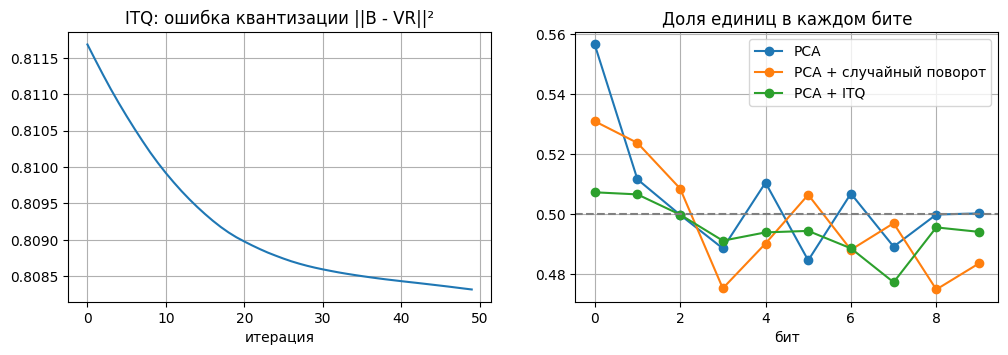

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(binz["PCA + ITQ"].quant_loss)
ax[0].set(title="ITQ: ошибка квантизации ||B - VR||²", xlabel="итерация")
ax[0].grid()

for name, b in binz.items():
    ax[1].plot(b.transform(X).mean(0), marker="o", label=name)
ax[1].axhline(0.5, color="gray", ls="--")
ax[1].set(title="Доля единиц в каждом бите", xlabel="бит")
ax[1].legend()
plt.grid()
plt.show()

In [10]:
itq = binz["PCA + ITQ"]
for i in range(len(demo)):
    print(sc.word_code_table(demo_enc.words[i], demo_enc.doc_word_vecs(i), itq))

[('Я', '1010100011'), ('потерял', '1010100111'), ('ключ', '1010100011'), ('от', '1010100110'), ('входной', '1010100011'), ('двери', '1010100011')]
[('Мастер', '1010100001'), ('сделал', '1011000000'), ('дубликат', '1011000000'), ('ключа', '1010100011'), ('от', '0010100000'), ('квартиры', '1010100001')]
[('Этим', '0000100010'), ('ключом', '0001100011'), ('открыли', '0001000011'), ('старый', '0000100011'), ('замок', '0000100011')]
[('Ключ', '1010100011'), ('шифрования', '0010100010'), ('хранится', '0010100110'), ('в', '0010100110'), ('аппаратном', '1010100010'), ('модуле', '0010100010')]
[('Секретный', '1010111011'), ('ключ', '1010111011'), ('RSA', '1010111011'), ('нельзя', '1010111110'), ('передавать', '1010111111'), ('по', '1010111110'), ('почте', '1010111011')]


## 5. Семантические коды + BM25

Каждое слово → `§h<номер хеша>_<биты>§`. Несколько независимых хешей (разные повороты ITQ)
смягчают проблему границы ячеек: соседние точки чаще совпадают хотя бы по одному хешу.

In [14]:
r = sc.codes_experiment(doc_enc, q_enc, data.qrels, n_bits=N_BITS, n_hashes=1, method="itq")
print(sc.coded_text(doc_enc.words[0][:30], r["doc_codes"][0], fields_d["entities"][0]))
print()
print(sc.coded_text(q_enc.words[0], r["query_codes"][0], fields_q["entities"][0]))
pd.DataFrame(sc.strip_heavy([r]))

Следующий§h0_0010001100§ сезон§h0_0011001000§ ЦСКА§h0_1010001000§ должен§h0_1011001110§ был§h0_0001001100§ начать§h0_1011001100§ во§h0_0011001100§ второй§h0_0010011000§ лиге§h0_0010001000§ но§h0_0010011100§ благодаря§h0_1011001100§ вмешательству§h0_1011001000§ премьер-министра§h0_1010001000§ страны§h0_0010001000§ Бойко§h0_1010011000§ Борисова§h0_1010001000§ который§h0_1010001100§ принял§h0_1011001100§ срочные§h0_1010010000§ и§h0_1010011000§ своевременные§h0_1010011100§ меры§h0_1011001110§ 31-кратный§h0_1010001000§ чемпион§h0_1110001001§ Болгарии§h0_0010001000§ напрямую§h0_1011011110§ вернулся§h0_1011001110§ в§h0_0011001100§ элитный§h0_0010001000§ дивизион§h0_0010001000§
  сущности: ent:org:цска, ent:per:бойко_борисов, ent:loc:болгария

Как§h0_1100101111§ зовут§h0_1101101111§ Бречалова§h0_1100100011§ Удмуртия§h0_1100101011§
  сущности: ent:per:бречалов_удмуртия


,method,n_bits,n_hashes,k1,b,Recall@1,Recall@5,Recall@10,Recall@100,nDCG@10,MRR,vocab,index_MB,fit_s,search_ms_per_q
0,itq,10,1,1.2000,0.7500,0.0128,0.0706,0.1192,0.4173,0.0629,0.0638,1024,0.5605,2.9425,0.0593


In [15]:
rows = []
for n_bits in BITS_GRID:
    for n_hashes in HASHES_GRID:
        for method in ["pca", "itq"]:
            rows.append(sc.codes_experiment(doc_enc, q_enc, data.qrels, n_bits=n_bits, n_hashes=n_hashes, method=method))
grid = pd.DataFrame(sc.strip_heavy(rows))
grid.sort_values("nDCG@10", ascending=False)

,method,n_bits,n_hashes,k1,b,Recall@1,Recall@5,Recall@10,Recall@100,nDCG@10,MRR,vocab,index_MB,fit_s,search_ms_per_q
23,itq,14,4,1.2000,0.7500,0.0442,0.1472,0.2125,0.5314,0.1321,0.1407,62483,3.5726,14.9350,0.0615
11,itq,10,4,1.2000,0.7500,0.0408,0.1403,0.1950,0.5296,0.1221,0.1324,4096,2.2295,11.7414,0.0542
17,itq,12,4,1.2000,0.7500,0.0444,0.1356,0.1883,0.5535,0.1167,0.1194,16374,2.9125,13.4048,0.0692
15,itq,12,2,1.2000,0.7500,0.0428,0.1178,0.1750,0.4823,0.1081,0.1163,8186,1.4574,6.7764,0.0553
9,itq,10,2,1.2000,0.7500,0.0392,0.1150,0.1697,0.5152,0.1067,0.1149,2048,1.1195,5.9756,0.0517
21,itq,14,2,1.2000,0.7500,0.0508,0.0981,0.1517,0.4442,0.1020,0.1150,31292,1.7872,7.5528,0.0592
19,itq,14,1,1.2000,0.7500,0.0386,0.0911,0.1519,0.3316,0.0924,0.0987,15679,0.8920,3.7509,0.0479
13,itq,12,1,1.2000,0.7500,0.0336,0.0939,0.1521,0.4387,0.0907,0.0924,4095,0.7272,3.2534,0.0476
20,pca,14,2,1.2000,0.7500,0.0406,0.0958,0.1308,0.2572,0.0885,0.0969,32224,1.8525,2.1584,0.0606
18,pca,14,1,1.2000,0.7500,0.0406,0.0958,0.1308,0.2572,0.0885,0.0969,16112,0.9262,1.0560,0.0458


In [16]:
grid.pivot_table(index="n_bits", columns=["method", "n_hashes"], values="nDCG@10")

method      itq                  pca              
n_hashes      1      2      4      1      2      4
n_bits                                            
8        0.0541 0.0572 0.0691 0.0529 0.0529 0.0529
10       0.0629 0.1067 0.1221 0.0639 0.0639 0.0639
12       0.0907 0.1081 0.1167 0.0818 0.0818 0.0818
14       0.0924 0.1020 0.1321 0.0885 0.0885 0.0885

## 6. Автоэнкодер с бинарным слоем

Straight-through: на прямом проходе округление, градиент проходит как есть; шум перед сигмоидой.
Штрафы: баланс (каждый бит включён ~в половине случаев) и декорреляция бит.
Отдельно проверяем, что будет без штрафов.

[AE] epoch 15/15  loss=0.6252  rec=0.6224  balance=0.0019  decorr=0.0009
[AE] epoch 15/15  loss=0.6205  rec=0.6205  balance=0.0049  decorr=0.0019


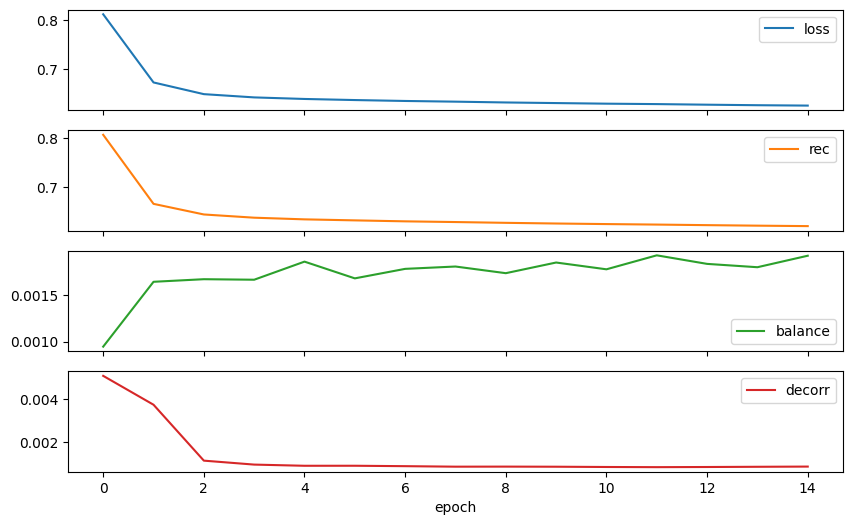

In [17]:
AE_KW = dict(hidden=512, epochs=15, noise=1.0)
r_ae = sc.codes_experiment(doc_enc, q_enc, data.qrels, n_bits=N_BITS, n_hashes=1, method="ae", **AE_KW)
r_ae_raw = sc.codes_experiment(doc_enc, q_enc, data.qrels, n_bits=N_BITS, n_hashes=1, method="ae",
                               w_balance=0, w_decorr=0, **AE_KW)
pd.DataFrame(r_ae["binarizers"][0].history).set_index("epoch").plot(subplots=True, figsize=(10, 6))
plt.show()

In [18]:
ae_stats = {
    "PCA + ITQ": sc.code_stats(itq, X),
    "AE со штрафами": sc.code_stats(r_ae["binarizers"][0], X),
    "AE без штрафов": sc.code_stats(r_ae_raw["binarizers"][0], X),
}
display(pd.DataFrame(ae_stats).T)
r_ae_raw["method"] = "ae (без штрафов)"
pd.DataFrame(sc.strip_heavy([r, r_ae, r_ae_raw]))

,used_codes,used_share,entropy_bits,max_entropy,top1_code_share,bit_balance_dev,mean_abs_bit_corr,near_zero_share
PCA + ITQ,1024.0000,1.0000,9.7020,10.0000,0.0111,0.0080,0.0486,0.0213
AE со штрафами,1024.0000,1.0000,9.7195,10.0000,0.0055,0.0030,0.0236,0.0206
AE без штрафов,1024.0000,1.0000,9.6516,10.0000,0.0075,0.0187,0.0394,0.0206


,method,n_bits,n_hashes,k1,b,Recall@1,Recall@5,Recall@10,Recall@100,nDCG@10,MRR,vocab,index_MB,fit_s,search_ms_per_q
0,itq,10,1,1.2000,0.7500,0.0128,0.0706,0.1192,0.4173,0.0629,0.0638,1024,0.5605,2.9425,0.0593
1,ae,10,1,1.2000,0.7500,0.0386,0.1044,0.1794,0.5302,0.1056,0.1130,1024,0.5340,9.1759,0.0493
2,ae (без штрафов),10,1,1.2000,0.7500,0.0319,0.1028,0.1628,0.5641,0.0949,0.1029,1024,0.5271,7.7520,0.0465


In [19]:
# лучший размер AE по сетке бит (n_hashes=1, чтобы не обучать много моделей)
rows_ae = [sc.codes_experiment(doc_enc, q_enc, data.qrels, n_bits=nb, method="ae", **AE_KW) for nb in BITS_GRID]
pd.DataFrame(sc.strip_heavy(rows_ae))

[AE] epoch 15/15  loss=0.6534  rec=0.6512  balance=0.0016  decorr=0.0007
[AE] epoch 15/15  loss=0.6252  rec=0.6224  balance=0.0019  decorr=0.0009
[AE] epoch 15/15  loss=0.6018  rec=0.5985  balance=0.0023  decorr=0.0010
[AE] epoch 15/15  loss=0.5799  rec=0.5762  balance=0.0027  decorr=0.0010


,method,n_bits,n_hashes,k1,b,Recall@1,Recall@5,Recall@10,Recall@100,nDCG@10,MRR,vocab,index_MB,fit_s,search_ms_per_q
0,ae,8,1,1.2000,0.7500,0.0336,0.0933,0.1389,0.5235,0.0886,0.1066,256,0.3819,8.0755,0.0483
1,ae,10,1,1.2000,0.7500,0.0386,0.1044,0.1794,0.5302,0.1056,0.1130,1024,0.5340,7.8329,0.0586
2,ae,12,1,1.2000,0.7500,0.0442,0.1292,0.1753,0.4850,0.1125,0.1223,4096,0.7092,7.6455,0.0691
3,ae,14,1,1.2000,0.7500,0.0331,0.1503,0.2233,0.4117,0.1258,0.1246,15506,0.8638,7.9375,0.0573


## 7. Точные сущности и гибрид

Телефоны, email, даты, суммы, номера — регулярками с нормализацией; имена, организации, топонимы — natasha.
Затем три поля BM25 с весами: коды, сущности, исходные слова (леммы).

In [20]:
sample = ("Звоните 8 (916) 123-45-67 или +7 916 1234567, пишите на Info@Example.RU. "
          "Договор № 2023/117 от 12.03.2023 на сумму 150 000 руб. подписал Иван Петров в Москве, ООО «Ромашка», 5 мая 2024.")
sc.extract_entities(sample, use_ner=USE_NER)

['ent:email:info@example.ru',
 'ent:phone:+79161234567',
 'ent:phone:+79161234567',
 'ent:date:2023-03-12',
 'ent:date:2024-05-05',
 'ent:money:150000RUB',
 'ent:num:2023/117',
 'ent:per:иван_петров',
 'ent:loc:москва',
 'ent:org:ооо_ромашка']

In [21]:
best = max(rows, key=lambda x: x["nDCG@10"])
print("лучшие коды:", best["method"], best["n_bits"], "бит,", best["n_hashes"], "хеш(а)")
fields_d["codes"], fields_q["codes"] = best["doc_codes"], best["query_codes"]

hybrid = sc.MultiFieldBM25({"codes": 1.0, "entities": 1.0, "lemmas": 1.0}).fit(fields_d)
FS = hybrid.field_scores(fields_q)

w_rows = []
for w_c in [0, 0.5, 1.0]:
    for w_e in [0, 1.0, 2.0, 4.0]:
        for w_l in [0, 0.5, 1.0, 2.0]:
            if w_c or w_e or w_l:
                w = {"codes": w_c, "entities": w_e, "lemmas": w_l}
                w_rows.append({**w, **sc.evaluate(sc.combine_scores(FS, w), data.qrels)})
weights = pd.DataFrame(w_rows).sort_values("nDCG@10", ascending=False)
weights.head(10)

лучшие коды: itq 14 бит, 4 хеш(а)


,codes,entities,lemmas,Recall@1,Recall@5,Recall@10,Recall@100,nDCG@10,MRR
6,0.0000,1.0000,2.0000,0.4360,0.7538,0.8133,0.9292,0.6996,0.7010
5,0.0000,1.0000,1.0000,0.4244,0.7479,0.8075,0.9292,0.6922,0.6932
10,0.0000,2.0000,2.0000,0.4244,0.7479,0.8075,0.9292,0.6922,0.6932
2,0.0000,0.0000,2.0000,0.4224,0.7418,0.7947,0.9281,0.6858,0.6915
1,0.0000,0.0000,1.0000,0.4224,0.7418,0.7947,0.9281,0.6858,0.6915
0,0.0000,0.0000,0.5000,0.4224,0.7418,0.7947,0.9281,0.6858,0.6915
4,0.0000,1.0000,0.5000,0.4155,0.7354,0.8008,0.9292,0.6825,0.6827
14,0.0000,4.0000,2.0000,0.4155,0.7354,0.8008,0.9292,0.6825,0.6827
9,0.0000,2.0000,1.0000,0.4155,0.7354,0.8008,0.9292,0.6825,0.6827
26,0.5000,2.0000,2.0000,0.4127,0.7263,0.8184,0.9511,0.6809,0.6821


In [22]:
best_w = weights.iloc[0][["codes", "entities", "lemmas"]].to_dict()
S_hybrid, t = sc.timed(hybrid.score_matrix, fields_q, best_w)

results[f"коды PCA-ITQ ({r['n_bits']} бит, 1 хеш)"] = {k: r[k] for k in results["BGE-M3 dense"]}
results[f"коды лучшие ({best['method']}, {best['n_bits']} бит, {best['n_hashes']} хеш)"] = {k: best[k] for k in results["BGE-M3 dense"]}
results[f"коды AE ({N_BITS} бит)"] = {k: r_ae[k] for k in results["BGE-M3 dense"]}
results["гибрид: коды + сущности + слова"] = sc.evaluate(S_hybrid, data.qrels)
results["RRF: гибрид + dense"] = sc.evaluate(sc.rrf([S_hybrid, S_dense]), data.qrels)

sizes[f"коды PCA-ITQ ({r['n_bits']} бит, 1 хеш)"] = r["index_MB"] * 2 ** 20
sizes[f"коды лучшие ({best['method']}, {best['n_bits']} бит, {best['n_hashes']} хеш)"] = best["index_MB"] * 2 ** 20
sizes[f"коды AE ({N_BITS} бит)"] = r_ae["index_MB"] * 2 ** 20
sizes["гибрид: коды + сущности + слова"] = hybrid.size_bytes()
speed[f"коды PCA-ITQ ({r['n_bits']} бит, 1 хеш)"] = r["search_ms_per_q"] / 1000
speed[f"коды лучшие ({best['method']}, {best['n_bits']} бит, {best['n_hashes']} хеш)"] = best["search_ms_per_q"] / 1000
speed[f"коды AE ({N_BITS} бит)"] = r_ae["search_ms_per_q"] / 1000
speed["гибрид: коды + сущности + слова"] = t / len(data.queries)
print("веса:", best_w)

веса: {'codes': 0.0, 'entities': 1.0, 'lemmas': 2.0}


## 8. Подбор k1 и b

Частота кода в документе может отражать тему и длину текста, поэтому насыщение (k1) и нормировку длины (b) стоит подобрать.
Коды не переобучаются: передаём готовые бинаризаторы.

In [23]:
kb_rows = [
    sc.codes_experiment(doc_enc, q_enc, data.qrels, n_bits=best["n_bits"], n_hashes=best["n_hashes"],
                        method=best["method"], k1=k1, b=b, binarizers=best["binarizers"])
    for k1 in [0.3, 0.6, 1.2, 2.0, 3.0] for b in [0.0, 0.3, 0.6, 0.75, 1.0]
]
kb = pd.DataFrame(sc.strip_heavy(kb_rows))
kb.pivot_table(index="k1", columns="b", values="nDCG@10")

b,0.0000,0.3000,0.6000,0.7500,1.0000
k1,,,,,
0.3000,0.1301,0.1326,0.1298,0.1322,0.1316
0.6000,0.1290,0.1337,0.1327,0.1320,0.1296
1.2000,0.1330,0.1332,0.1331,0.1321,0.1318
2.0000,0.1293,0.1348,0.1311,0.1287,0.1259
3.0000,0.1267,0.1351,0.1291,0.1267,0.1244


## 9. Итоги

Качество, размер индекса (без словаря и без модели) и время поиска на один запрос (без кодирования запроса моделью).

In [24]:
summary = pd.DataFrame(results).T
summary["index_MB"] = pd.Series(sizes) / 2 ** 20
summary["search_ms_per_q"] = pd.Series(speed) * 1000
summary.sort_values("nDCG@10", ascending=False)

,Recall@1,Recall@5,Recall@10,Recall@100,nDCG@10,MRR,index_MB,search_ms_per_q
BGE-M3 ColBERT,0.6891,0.9460,0.9758,0.9911,0.9354,0.9408,591.9043,14.7996
BGE-M3 dense,0.6880,0.9463,0.9692,0.9922,0.9320,0.9403,4.8574,0.0565
RRF: гибрид + dense,0.5769,0.8504,0.9192,0.9928,0.8366,0.8389,NaN,NaN
гибрид: коды + сущности + слова,0.4360,0.7538,0.8133,0.9292,0.6996,0.7010,4.7362,0.1434
BM25 по словам (леммы),0.4224,0.7418,0.7947,0.9281,0.6858,0.6915,1.0122,0.0636
"коды лучшие (itq, 14 бит, 4 хеш)",0.0442,0.1472,0.2125,0.5314,0.1321,0.1407,3.5726,0.0615
коды AE (10 бит),0.0386,0.1044,0.1794,0.5302,0.1056,0.1130,0.5340,0.0493
"коды PCA-ITQ (10 бит, 1 хеш)",0.0128,0.0706,0.1192,0.4173,0.0629,0.0638,0.5605,0.0593


In [25]:
QI = 0   # номер запроса для просмотра
for name, S in [("BM25 по словам", S_words), ("dense", S_dense), ("гибрид", S_hybrid)]:
    print(f"--- {name}")
    sc.show_top(S, data, QI, k=5)

--- BM25 по словам
Запрос: Как зовут Бречалова Удмуртия?
  1.   [8.748] Первый куплет посвящён трём цветам Флага и Герба Удмуртской Республики, символизирующим собой красное солнце (солярный з
  2.   [8.611] 2015 — Приз им. Александра Абдулова «За лучшую женскую роль в российском дебютном фильме» (вместе с Мариной Васильевой) 
  3.   [8.232] 29 ноября 2011 года главой Удмуртской Республики Александром Волковым подписан Указ о присвоении Ижевску звания «Город т
  4. ✓ [7.470] Алекса́ндр Влади́мирович Бреча́лов (род. 18 ноября 1973, п. Тлюстенхабль, Теучежский район, Адыгейская АО, РСФСР, СССР) 
  5.   [6.779] 20 марта 1969 года в Гибралтаре был зарегистрирован брак Джона Леннона и Йоко Оно. После женитьбы Леннон сменил своё вто
--- dense
Запрос: Как зовут Бречалова Удмуртия?
  1. ✓ [0.674] Алекса́ндр Влади́мирович Бреча́лов (род. 18 ноября 1973, п. Тлюстенхабль, Теучежский район, Адыгейская АО, РСФСР, СССР) 
  2.   [0.429] Юлия Викторовна Нача́лова (полная фамилия — Началова-Алдонина; 3